<a href="https://colab.research.google.com/github/ShalakaEranga/DriveHealth-Comparative-Fault-Diagnosis-Using-Classical-vs-Deep-Learning-Methods/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Clone the repo

In [3]:
import os

REPO_URL = "https://github.com/ShalakaEranga/DriveHealth-Comparative-Fault-Diagnosis-Using-Classical-vs-Deep-Learning-Methods.git"
REPO_DIR = "drivehealth"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull

%cd {REPO_DIR}

Cloning into 'drivehealth'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 14 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 8.00 KiB | 2.67 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/drivehealth


Install the extra packages

In [4]:
!pip install -q xgboost imbalanced-learn shap ucimlrepo

Make src/ importable, set the seed, check the GPU

In [5]:
import sys, random
import numpy as np
import torch

sys.path.append(os.getcwd())      # lets you write: from src.preprocessing import ...

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


Mount Google Drive

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Download the five files into data/raw/

In [7]:
!pip install -q gdown

import gdown, os

os.makedirs("data/raw", exist_ok=True)

file_ids = [
    "17SCB0DjQF8Tb5uDXBAJbQw8363Pj6RCe",
    "1w8fIhblYWSnaB5s2dvIgfJEKwNCmtQEE",
    "1AeFBxTGpZamaQEGoguQYtPFeB3RmpguC",
    "14CjuHRc-bR76kE5uE7gqZEjygkzWhjGZ",
    "1TNkEUOcKlAQGG7nSvFZLUsbGuNzWXeQl",
    "1GyWo_B6i_gG5LPbvNTz6oZvMKz6YGiNa",
]

for fid in file_ids:
    # trailing "/" makes gdown keep the original file name
    gdown.download(id=fid, output="data/raw/", quiet=False)

print("\nFiles in data/raw:")
for f in sorted(os.listdir("data/raw")):
    size_mb = os.path.getsize(os.path.join("data/raw", f)) / 1e6
    print(f"  {f}  ({size_mb:.2f} MB)")

Downloading...
From: https://drive.google.com/uc?id=17SCB0DjQF8Tb5uDXBAJbQw8363Pj6RCe
To: /content/drivehealth/data/raw/NEV_fault_dataset.csv
100%|██████████| 1.54M/1.54M [00:00<00:00, 13.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1w8fIhblYWSnaB5s2dvIgfJEKwNCmtQEE
To: /content/drivehealth/data/raw/NEV_fault_testing_dataset.csv
100%|██████████| 463k/463k [00:00<00:00, 963kB/s]
Downloading...
From: https://drive.google.com/uc?id=1AeFBxTGpZamaQEGoguQYtPFeB3RmpguC
To: /content/drivehealth/data/raw/NEV_fault_training_dataset.csv
100%|██████████| 1.08M/1.08M [00:00<00:00, 11.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=14CjuHRc-bR76kE5uE7gqZEjygkzWhjGZ
To: /content/drivehealth/data/raw/OBD2 Powertrain Diagnostic.csv
100%|██████████| 242k/242k [00:00<00:00, 701kB/s]
Downloading...
From: https://drive.google.com/uc?id=1TNkEUOcKlAQGG7nSvFZLUsbGuNzWXeQl
To: /content/drivehealth/data/raw/ai4i2020.csv
100%|██████████| 522k/522k [00:00<00:00, 7.07MB/s]
Downloading...
F


Files in data/raw:
  NEV_fault_dataset.csv  (1.54 MB)
  NEV_fault_testing_dataset.csv  (0.46 MB)
  NEV_fault_training_dataset.csv  (1.08 MB)
  OBD2 Powertrain Diagnostic.csv  (0.24 MB)
  OBD_II_Combined_Live1_to_Live39.csv  (16.23 MB)
  ai4i2020.csv  (0.52 MB)


Load and preview all datasets

In [8]:
import pandas as pd, glob, os
pd.set_option("display.max_columns", 50)

datasets = {}
for path in sorted(glob.glob("data/raw/*.csv")):
    name = os.path.splitext(os.path.basename(path))[0]
    try:
        d = pd.read_csv(path)
    except UnicodeDecodeError:
        d = pd.read_csv(path, encoding="latin-1")
    datasets[name] = d

    print("=" * 70)
    print(name, "| shape:", d.shape)
    print("columns:", list(d.columns))
    display(d.head(3))

NEV_fault_dataset | shape: (11000, 8)
columns: ['Voltage (V)', 'Current (A)', 'Motor Speed (RPM)', 'Temperature (°C)', 'Vibration (g)', 'Ambient Temp (°C)', 'Humidity (%)', 'Fault Label']


,Voltage (V),Current (A),Motor Speed (RPM),Temperature (°C),Vibration (g),Ambient Temp (°C),Humidity (%),Fault Label
0,0.938922,0.199535,0.544403,0.239508,0.301284,0.582435,0.397340,0.0
1,0.804854,0.597188,0.073416,0.180373,0.920876,0.128203,0.124523,1.0
2,0.949877,0.426896,0.083007,0.251436,0.610996,0.714957,0.003283,1.0


NEV_fault_testing_dataset | shape: (3300, 8)
columns: ['Voltage (V)', 'Current (A)', 'Motor Speed (RPM)', 'Temperature (°C)', 'Vibration (g)', 'Ambient Temp (°C)', 'Humidity (%)', 'Fault Label']


,Voltage (V),Current (A),Motor Speed (RPM),Temperature (°C),Vibration (g),Ambient Temp (°C),Humidity (%),Fault Label
0,0.965884,0.805192,0.999561,0.506581,0.329047,0.941782,0.253191,0.0
1,0.624323,0.325016,0.202624,0.592170,0.167791,0.819961,0.212062,3.0
2,0.662495,0.165748,0.817081,0.844995,0.052487,0.669907,0.524231,3.0


NEV_fault_training_dataset | shape: (7700, 8)
columns: ['Voltage (V)', 'Current (A)', 'Motor Speed (RPM)', 'Temperature (°C)', 'Vibration (g)', 'Ambient Temp (°C)', 'Humidity (%)', 'Fault Label']


,Voltage (V),Current (A),Motor Speed (RPM),Temperature (°C),Vibration (g),Ambient Temp (°C),Humidity (%),Fault Label
0,0.231994,0.374537,0.236504,0.819322,0.231012,0.468886,0.983225,3.0
1,0.808943,0.695532,0.155385,0.299372,0.494508,0.312739,0.658743,1.0
2,0.530818,0.014734,0.429550,0.041442,0.306601,0.537728,0.213263,2.0


... (3 outputs left out)

/tmp/ipykernel_361/2369573937.py:8: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(path)


,Source_File,ENGINE_RUN_TINE (),ENGINE_RPM (),VEHICLE_SPEED (),THROTTLE (),ENGINE_LOAD (),COOLANT_TEMPERATURE (),LONG_TERM_FUEL_TRIM_BANK_1 (),SHORT_TERM_FUEL_TRIM_BANK_1 (),INTAKE_MANIFOLD_PRESSURE (),FUEL_TANK (),ABSOLUTE_THROTTLE_B (),PEDAL_D (),PEDAL_E (),COMMANDED_THROTTLE_ACTUATOR (),FUEL_AIR_COMMANDED_EQUIV_RATIO (),ABSOLUTE_BAROMETRIC_PRESSURE (),RELATIVE_THROTTLE_POSITION (),INTAKE_AIR_TEMP (),TIMING_ADVANCE (),CATALYST_TEMPERATURE_BANK1_SENSOR1 (),CATALYST_TEMPERATURE_BANK1_SENSOR2 (),CONTROL_MODULE_VOLTAGE (),COMMANDED_EVAPORATIVE_PURGE (),TIME_RUN_WITH_MIL_ON (),TIME_SINCE_TROUBLE_CODES_CLEARED (),DISTANCE_TRAVELED_WITH_MIL_ON (),WARM_UPS_SINCE_CODES_CLEARED ()
0,live1,0,0.0,0,17.647058,0.0,25,-2.34375,0.0,101,36.07843,49.803921,16.078432,31.764706,13.333333,0,100,0.0,25,5.0,434.700012,295.100006,12.324,0.0,0.0,7835.0,0.0,255.0
1,live1,0,0.0,0,17.647058,0.0,25,-2.34375,0.0,101,36.07843,49.803921,16.078432,31.764706,13.333333,0,100,0.0,25,5.0,434.700012,295.100006,12.343,0.0,0.0,7835.0,0.0,255.0
2,live1,0,0.0,0,17.647058,0.0,25,-2.34375,0.0,101,36.07843,49.803921,16.078432,31.764706,13.333333,0,100,0.0,25,5.0,434.700012,295.100006,12.343,0.0,0.0,7835.0,0.0,255.0


ai4i2020 | shape: (10000, 14)
columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


Dataset inventory (size, missing values, duplicates)

In [9]:
summary = pd.DataFrame({
    name: {
        "rows": d.shape[0],
        "columns": d.shape[1],
        "missing_cells": int(d.isna().sum().sum()),
        "duplicate_rows": int(d.duplicated().sum()),
    }
    for name, d in datasets.items()
}).T
summary

,rows,columns,missing_cells,duplicate_rows
NEV_fault_dataset,11000,8,0,0
NEV_fault_testing_dataset,3300,8,0,0
NEV_fault_training_dataset,7700,8,0,0
OBD2 Powertrain Diagnostic,3712,3,0,0
OBD_II_Combined_Live1_to_Live39,97281,28,6870,7756
ai4i2020,10000,14,0,0


Check how the three NEV files relate

In [10]:
full  = datasets["NEV_fault_dataset"]
train = datasets["NEV_fault_training_dataset"]
test  = datasets["NEV_fault_testing_dataset"]

print("full :", full.shape)
print("train:", train.shape)
print("test :", test.shape)
print("train + test rows:", train.shape[0] + test.shape[0])
print("Same columns in all three:", list(full.columns) == list(train.columns) == list(test.columns))

full : (11000, 8)
train: (7700, 8)
test : (3300, 8)
train + test rows: 11000
Same columns in all three: True


EDA helper function

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

def quick_eda(df, name):
    print(f"===== {name} =====")
    df.info()
    display(df.describe().T)

    missing = df.isna().sum()
    print("\nColumns with missing values:", missing[missing > 0].to_dict())
    print("Duplicate rows:", df.duplicated().sum())

    # Columns with few unique values are label / category candidates
    cands = [c for c in df.columns if df[c].nunique() <= 10]
    print("\nPossible label/categorical columns:", cands)
    for c in cands:
        print(f"\n{c}:\n{df[c].value_counts()}")

    # Numeric distributions and correlations
    num = df.select_dtypes("number")
    num.hist(figsize=(14, 9), bins=30)
    plt.suptitle(f"{name}: feature distributions")
    plt.tight_layout(); plt.show()

    plt.figure(figsize=(9, 7))
    sns.heatmap(num.corr(), cmap="coolwarm", center=0)
    plt.title(f"{name}: correlation heatmap")
    plt.show()

EDA: NEV drivetrain fault dataset (primary)

===== NEV_fault_dataset =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Voltage (V)        11000 non-null  float64
 1   Current (A)        11000 non-null  float64
 2   Motor Speed (RPM)  11000 non-null  float64
 3   Temperature (°C)   11000 non-null  float64
 4   Vibration (g)      11000 non-null  float64
 5   Ambient Temp (°C)  11000 non-null  float64
 6   Humidity (%)       11000 non-null  float64
 7   Fault Label        11000 non-null  float64
dtypes: float64(8)
memory usage: 687.6 KB


,count,mean,std,min,25%,50%,75%,max
Voltage (V),11000.0,0.728576,0.224415,0.0,0.612900,0.797613,0.891521,1.0
Current (A),11000.0,0.431700,0.245215,0.0,0.237031,0.396222,0.604094,1.0
Motor Speed (RPM),11000.0,0.443010,0.256147,0.0,0.229121,0.413228,0.640606,1.0
Temperature (°C),11000.0,0.380225,0.229912,0.0,0.197145,0.370151,0.520455,1.0
Vibration (g),11000.0,0.281481,0.240546,0.0,0.109902,0.217818,0.345722,1.0
Ambient Temp (°C),11000.0,0.495347,0.286040,0.0,0.249639,0.490943,0.743677,1.0
Humidity (%),11000.0,0.500356,0.290172,0.0,0.246695,0.503985,0.749887,1.0
Fault Label,11000.0,1.090909,1.164257,0.0,0.000000,1.000000,2.000000,3.0



Columns with missing values: {}
Duplicate rows: 0

Possible label/categorical columns: ['Fault Label']

Fault Label:
Fault Label
0.0    5000
1.0    2000
2.0    2000
3.0    2000
Name: count, dtype: int64


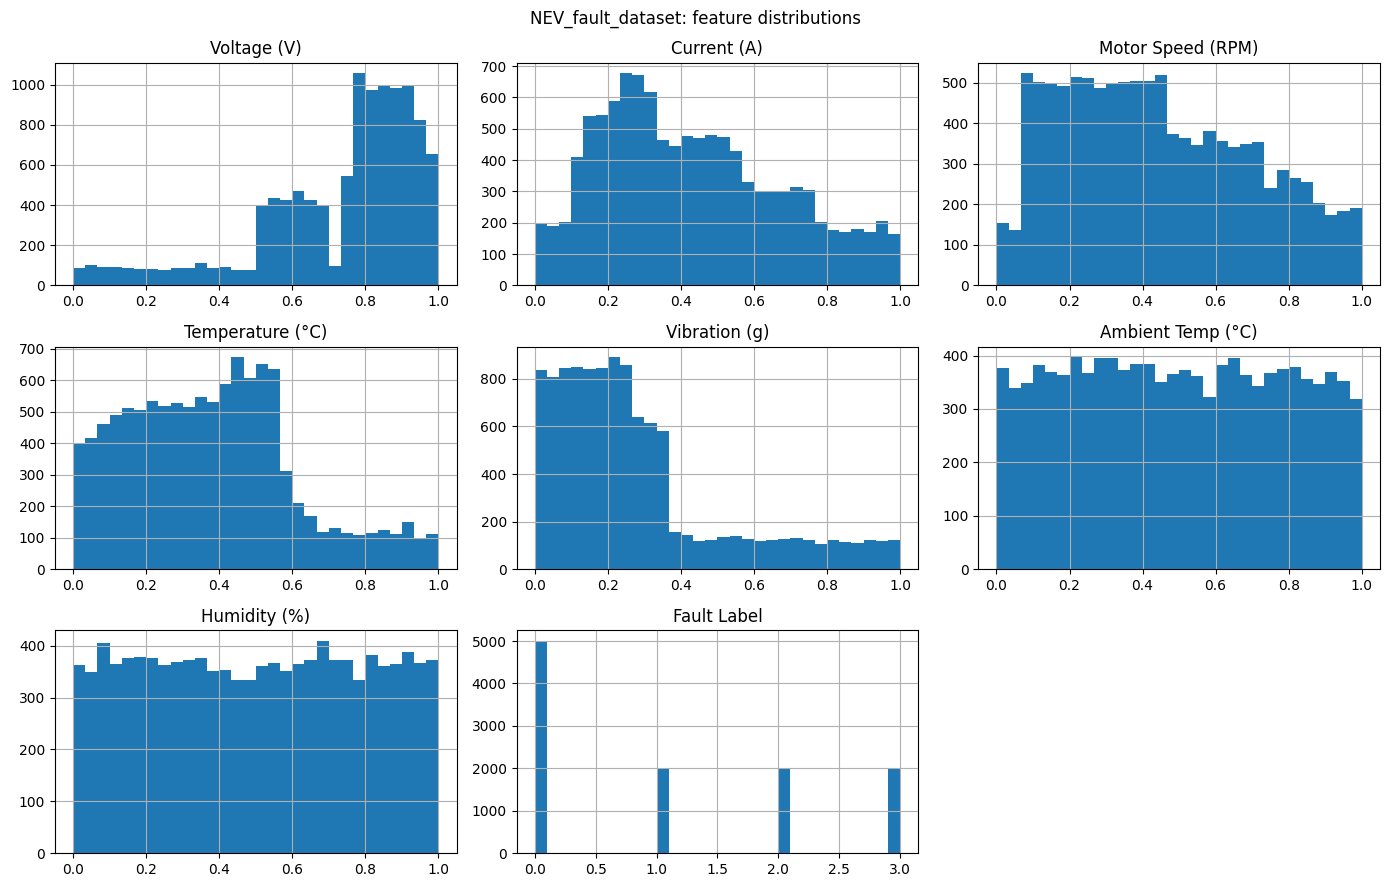

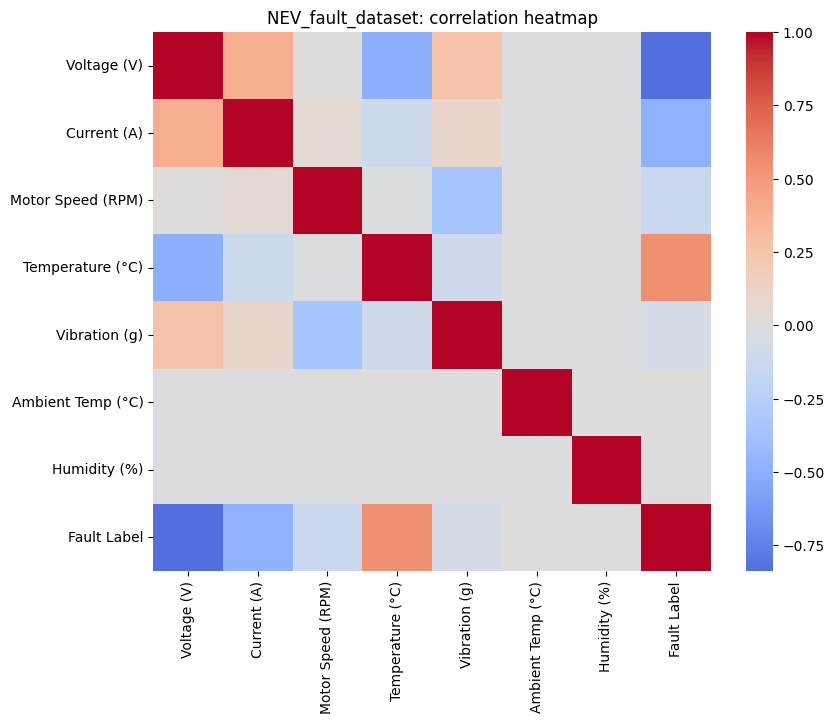

In [12]:
quick_eda(datasets["NEV_fault_dataset"], "NEV_fault_dataset")

EDA: AI4I 2020 predictive maintenance (fallback)

===== ai4i2020 =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes:

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0



Columns with missing values: {}
Duplicate rows: 0

Possible label/categorical columns: ['Type', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Type:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Machine failure:
Machine failure
0    9661
1     339
Name: count, dtype: int64

TWF:
TWF
0    9954
1      46
Name: count, dtype: int64

HDF:
HDF
0    9885
1     115
Name: count, dtype: int64

PWF:
PWF
0    9905
1      95
Name: count, dtype: int64

OSF:
OSF
0    9902
1      98
Name: count, dtype: int64

RNF:
RNF
0    9981
1      19
Name: count, dtype: int64


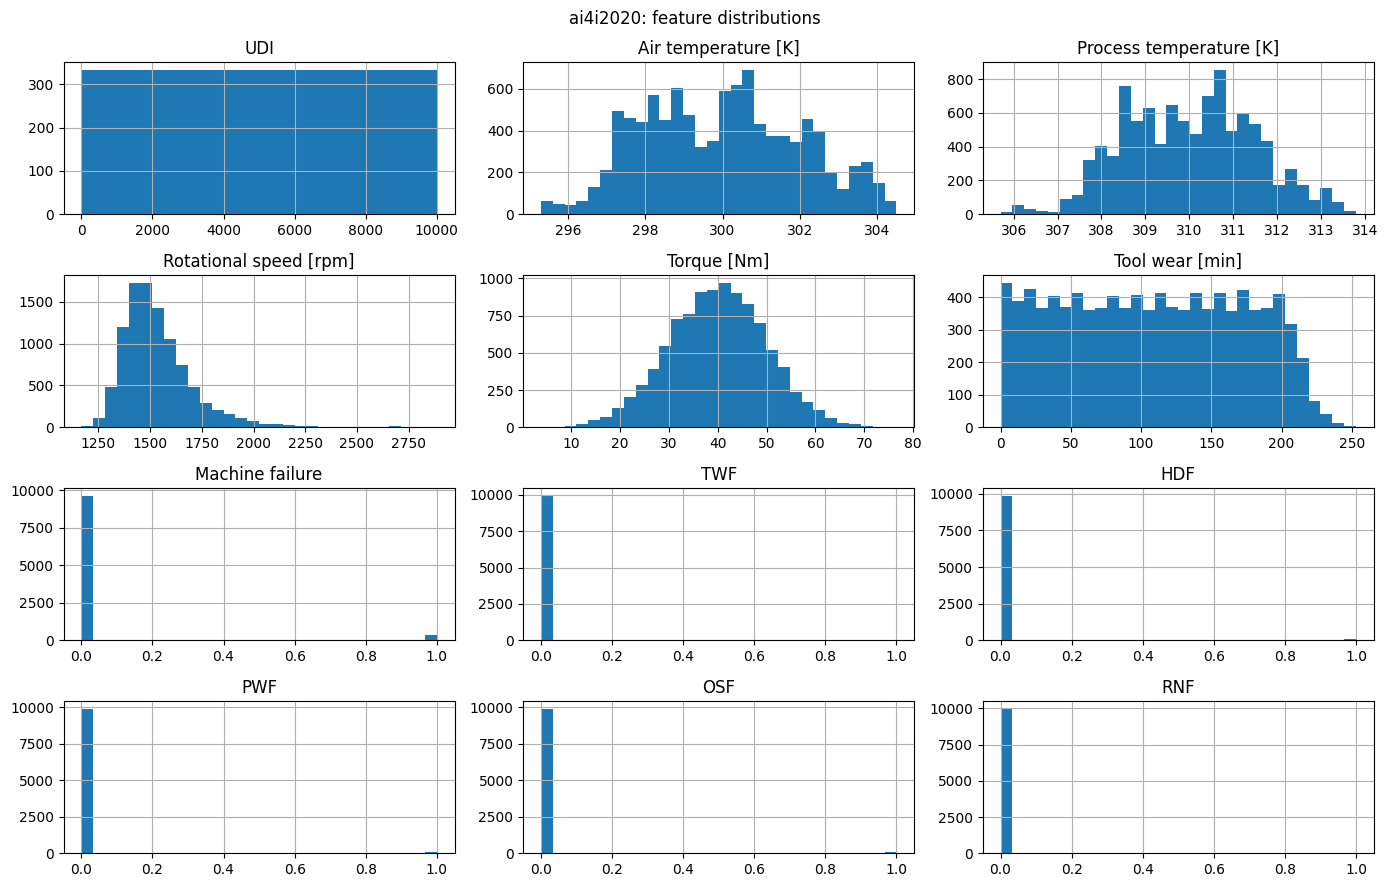

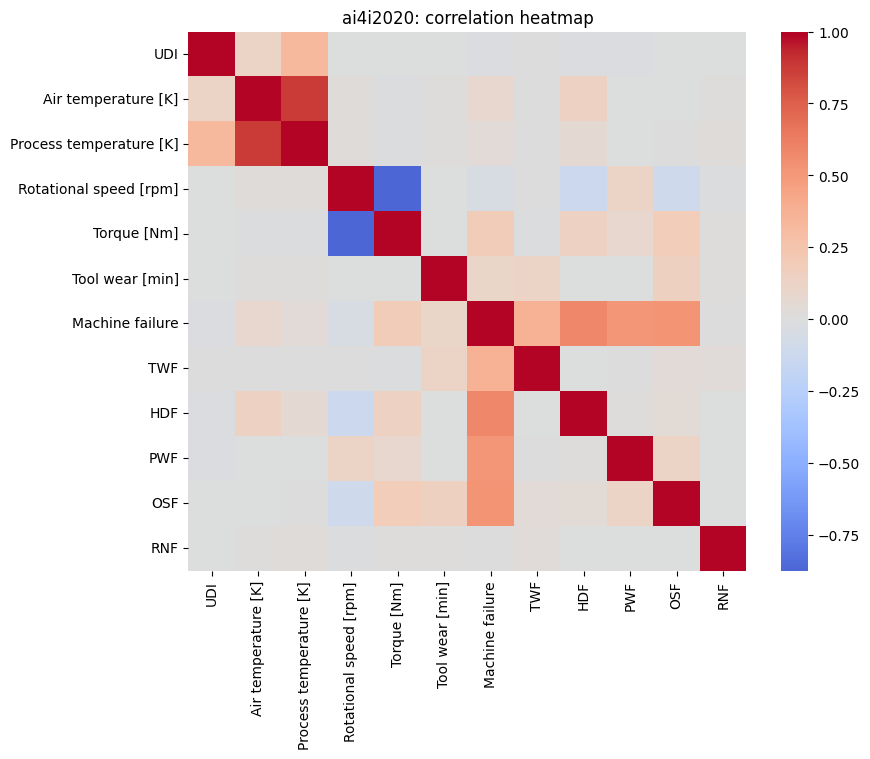

In [13]:
quick_eda(datasets["ai4i2020"], "ai4i2020")

EDA: OBD-II sensor data and DTC reference

In [14]:
print(datasets["OBD_II_Combined_Live1_to_Live39"].shape)
display(datasets["OBD_II_Combined_Live1_to_Live39"].describe().T)

display(datasets["OBD2 Powertrain Diagnostic"].head(15))

(97281, 28)


,count,mean,std,min,25%,50%,75%,max
ENGINE_RUN_TINE (),97281.0,663.844697,428.087473,0.000000,308.000000,621.000000,968.000000,1893.000000
ENGINE_RPM (),97281.0,1273.418216,440.424722,0.000000,858.500000,1296.000000,1615.500000,2973.250000
VEHICLE_SPEED (),97281.0,26.690227,19.517071,0.000000,9.000000,27.000000,41.000000,95.000000
THROTTLE (),97281.0,19.545874,3.758433,13.333000,17.254902,18.823530,20.784313,78.823532
ENGINE_LOAD (),97281.0,35.721430,15.547916,0.000000,25.882353,30.588236,40.392159,100.000000
COOLANT_TEMPERATURE (),97281.0,82.142854,12.559864,21.000000,86.000000,87.000000,88.000000,96.000000
LONG_TERM_FUEL_TRIM_BANK_1 (),97281.0,-0.221965,2.526366,-7.812500,-2.343750,0.000000,1.562500,7.031200
SHORT_TERM_FUEL_TRIM_BANK_1 (),97281.0,-0.129763,3.916770,-20.312500,-2.343750,0.000000,2.343750,14.843750
INTAKE_MANIFOLD_PRESSURE (),97281.0,36.698965,15.892935,17.000000,27.000000,32.000000,41.000000,102.000000
FUEL_TANK (),97281.0,40.368430,16.077220,8.627451,27.843138,36.078430,52.549019,90.980392


,Code,Trouble Code System,Condition Description
0,P0000,Powertrain,ISO/SAE Reserved
1,P0001,Powertrain,Fuel Volume Regulator Control Circuit/Open
2,P0002,Powertrain,Fuel Volume Regulator Control Circuit Range/Pe...
3,P0003,Powertrain,Fuel Volume Regulator Control Circuit Low
4,P0004,Powertrain,Fuel Volume Regulator Control Circuit High
5,P0005,Powertrain,Fuel Shutoff Valve Control Circuit/Open
6,P0006,Powertrain,Fuel Shutoff Valve Control Circuit Low
7,P0007,Powertrain,Fuel Shutoff Valve Control Circuit High
8,P0008,Powertrain,Engine Positions System Performance Bank 1
9,P0009,Powertrain,Engine Position System Performance Bank 2
